In [1]:
import pandas, numpy, sklearn.preprocessing, sklearn.metrics, sklearn.model_selection, sklearn.impute, sklearn.neural_network, matplotlib.pyplot, pickle

In [2]:
dataframe = pandas.read_csv("data/student_academic_burnout.csv")
dataframe

,weekly_study_hours,sleep_duration_hours,enrolled_credits,daily_screen_time_hours,previous_semester_gpa,commute_time_minutes,burnout_risk_level
0,27.7,6.5,20,9.1,86.7,11,1
1,15.6,7.2,17,4.0,100.0,52,0
2,31.8,6.2,18,9.3,65.3,12,1
3,33.5,6.1,25,NaN,90.9,44,2
4,7.4,7.0,14,6.6,78.8,18,0
...,...,...,...,...,...,...,...
895,34.4,7.4,18,13.2,66.0,39,1
896,18.9,7.2,16,5.7,74.0,35,0
897,17.2,6.9,17,5.3,58.8,55,1
898,29.3,6.9,17,3.1,80.3,9,1


In [3]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   weekly_study_hours       900 non-null    float64
 1   sleep_duration_hours     882 non-null    float64
 2   enrolled_credits         900 non-null    int64  
 3   daily_screen_time_hours  882 non-null    float64
 4   previous_semester_gpa    900 non-null    float64
 5   commute_time_minutes     900 non-null    int64  
 6   burnout_risk_level       900 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 49.3 KB


In [4]:
dataframe.describe()

,weekly_study_hours,sleep_duration_hours,enrolled_credits,daily_screen_time_hours,previous_semester_gpa,commute_time_minutes,burnout_risk_level
count,900.000000,882.000000,900.000000,882.000000,900.000000,900.000000,900.000000
mean,24.616556,6.584467,17.844444,7.059751,77.803889,32.017778,0.900000
std,8.856960,1.015720,3.684773,2.317882,8.820664,20.016948,0.768542
min,3.000000,3.600000,10.000000,1.000000,53.800000,5.000000,0.000000
25%,18.500000,5.900000,15.000000,5.400000,71.700000,18.000000,0.000000
50%,24.750000,6.600000,18.000000,7.050000,77.600000,27.000000,1.000000
75%,30.225000,7.300000,20.000000,8.600000,83.300000,40.250000,1.250000
max,53.600000,9.500000,28.000000,14.000000,100.000000,120.000000,2.000000


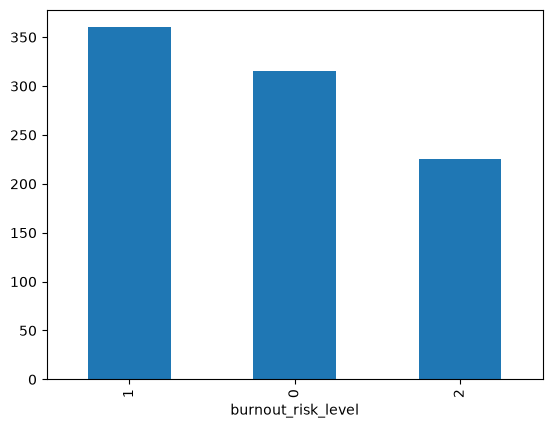

In [5]:
dataframe[dataframe.columns[-1]].value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [6]:
scaler = sklearn.preprocessing.StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [7]:
imputer = sklearn.impute.SimpleImputer(missing_values=numpy.nan, strategy="mean")
imputer

,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. If a feature has nomissing values at fit/train time, the feature won't appear onthe missing indicator even if there are missing values attransform/test time.",False
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",False


In [8]:
X = dataframe[dataframe.columns[0:-1]]
Y = dataframe[dataframe.columns[-1]]

In [9]:
X_train, X_test, Y_train, Y_test = sklearn.model_selection.train_test_split(X, Y, stratify=Y, test_size=0.3, random_state=42)

In [10]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 630 entries, 479 to 562
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   weekly_study_hours       630 non-null    float64
 1   sleep_duration_hours     618 non-null    float64
 2   enrolled_credits         630 non-null    int64  
 3   daily_screen_time_hours  616 non-null    float64
 4   previous_semester_gpa    630 non-null    float64
 5   commute_time_minutes     630 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 34.5 KB


In [11]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 270 entries, 454 to 445
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   weekly_study_hours       270 non-null    float64
 1   sleep_duration_hours     264 non-null    float64
 2   enrolled_credits         270 non-null    int64  
 3   daily_screen_time_hours  266 non-null    float64
 4   previous_semester_gpa    270 non-null    float64
 5   commute_time_minutes     270 non-null    int64  
dtypes: float64(4), int64(2)
memory usage: 14.8 KB


In [12]:
X_train = pandas.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pandas.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)

In [13]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 630 entries, 479 to 562
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   weekly_study_hours       630 non-null    float64
 1   sleep_duration_hours     630 non-null    float64
 2   enrolled_credits         630 non-null    float64
 3   daily_screen_time_hours  630 non-null    float64
 4   previous_semester_gpa    630 non-null    float64
 5   commute_time_minutes     630 non-null    float64
dtypes: float64(6)
memory usage: 34.5 KB


In [14]:
X_test.info()

<class 'pandas.DataFrame'>
Index: 270 entries, 454 to 445
Data columns (total 6 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   weekly_study_hours       270 non-null    float64
 1   sleep_duration_hours     270 non-null    float64
 2   enrolled_credits         270 non-null    float64
 3   daily_screen_time_hours  270 non-null    float64
 4   previous_semester_gpa    270 non-null    float64
 5   commute_time_minutes     270 non-null    float64
dtypes: float64(6)
memory usage: 14.8 KB


In [15]:
X_train = pandas.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pandas.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [16]:
model = sklearn.neural_network.MLPClassifier(hidden_layer_sizes=(45, ), activation="relu", solver="adam", learning_rate="constant", learning_rate_init=0.0001, alpha=0.0001, early_stopping=False, max_iter=2500, random_state=42)
model

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(45,)"
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.0001
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [17]:
model.fit(X_train, Y_train)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(45,)"
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.0001
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [18]:
sklearn.metrics.accuracy_score(Y_test, model.predict(X_test))

0.6925925925925925

In [19]:
print(sklearn.metrics.classification_report(Y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.76      0.78      0.77        95
           1       0.63      0.57      0.60       108
           2       0.69      0.76      0.72        67

    accuracy                           0.69       270
   macro avg       0.69      0.70      0.70       270
weighted avg       0.69      0.69      0.69       270



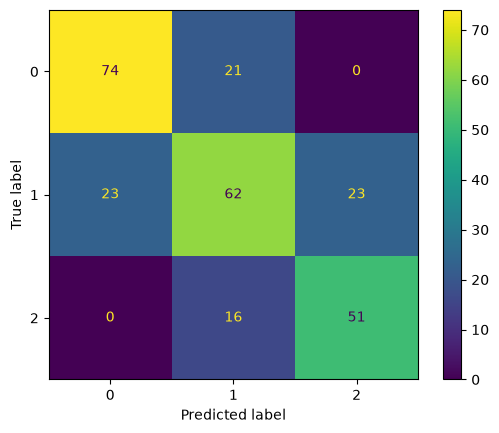

In [20]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_test, model.predict(X_test))).plot()
matplotlib.pyplot.show()

In [21]:
sklearn.metrics.accuracy_score(Y_train, model.predict(X_train))

0.7095238095238096

In [22]:
print(sklearn.metrics.classification_report(Y_train, model.predict(X_train)))

              precision    recall  f1-score   support

           0       0.79      0.76      0.78       220
           1       0.64      0.68      0.66       252
           2       0.72      0.68      0.70       158

    accuracy                           0.71       630
   macro avg       0.72      0.71      0.71       630
weighted avg       0.71      0.71      0.71       630



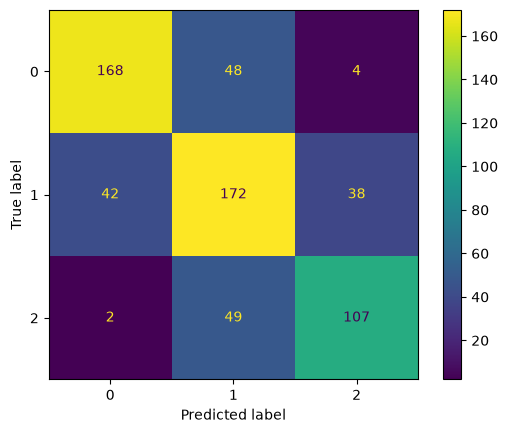

In [23]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y_train, model.predict(X_train))).plot()
matplotlib.pyplot.show()

In [24]:
X = pandas.DataFrame(imputer.fit_transform(X), columns=X.columns, index=X.index)

In [25]:
X = pandas.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)

In [26]:
model.fit(X, Y)

,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(45,)"
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.0001
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2500
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.For an example usage and visualization of varying regularization, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_alpha.py`.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the classifier will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when ``solver='sgd'``.",'constant'
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [27]:
sklearn.metrics.accuracy_score(Y, model.predict(X))

0.7133333333333334

In [28]:
print(sklearn.metrics.classification_report(Y, model.predict(X)))

              precision    recall  f1-score   support

           0       0.80      0.75      0.77       315
           1       0.63      0.69      0.66       360
           2       0.74      0.70      0.72       225

    accuracy                           0.71       900
   macro avg       0.73      0.71      0.72       900
weighted avg       0.72      0.71      0.71       900



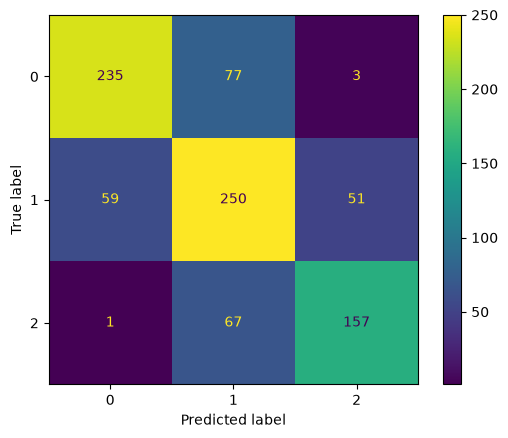

In [29]:
sklearn.metrics.ConfusionMatrixDisplay(sklearn.metrics.confusion_matrix(Y, model.predict(X))).plot()
matplotlib.pyplot.show()

In [30]:
with open("models/student_burnout_model.pickle", "wb+") as file:
    pickle.dump((imputer, scaler, model), file)